In [7]:
from PIL import Image
import pandas as pd
import numpy as np

from sklearn.model_selection import KFold, GroupKFold, StratifiedGroupKFold
from tqdm.auto import tqdm
tqdm.pandas()


In [8]:
DATA_ROOT = './data/' 

train_df = pd.read_csv(f'{DATA_ROOT}/train.csv')
train_df.head()

,sample_id,image_path,Sampling_Date,State,Species,Pre_GSHH_NDVI,Height_Ave_cm,target_name,target
0,ID1011485656__Dry_Clover_g,train/ID1011485656.jpg,2015/9/4,Tas,Ryegrass_Clover,0.62,4.6667,Dry_Clover_g,0.0000
1,ID1011485656__Dry_Dead_g,train/ID1011485656.jpg,2015/9/4,Tas,Ryegrass_Clover,0.62,4.6667,Dry_Dead_g,31.9984
2,ID1011485656__Dry_Green_g,train/ID1011485656.jpg,2015/9/4,Tas,Ryegrass_Clover,0.62,4.6667,Dry_Green_g,16.2751
3,ID1011485656__Dry_Total_g,train/ID1011485656.jpg,2015/9/4,Tas,Ryegrass_Clover,0.62,4.6667,Dry_Total_g,48.2735
4,ID1011485656__GDM_g,train/ID1011485656.jpg,2015/9/4,Tas,Ryegrass_Clover,0.62,4.6667,GDM_g,16.2750


In [9]:
train_df[['sample_id_prefix', 'sample_id_suffix']] = train_df.sample_id.str.split('__', expand=True)
train_df


,sample_id,image_path,Sampling_Date,State,Species,Pre_GSHH_NDVI,Height_Ave_cm,target_name,target,sample_id_prefix,sample_id_suffix
0,ID1011485656__Dry_Clover_g,train/ID1011485656.jpg,2015/9/4,Tas,Ryegrass_Clover,0.62,4.6667,Dry_Clover_g,0.0000,ID1011485656,Dry_Clover_g
1,ID1011485656__Dry_Dead_g,train/ID1011485656.jpg,2015/9/4,Tas,Ryegrass_Clover,0.62,4.6667,Dry_Dead_g,31.9984,ID1011485656,Dry_Dead_g
2,ID1011485656__Dry_Green_g,train/ID1011485656.jpg,2015/9/4,Tas,Ryegrass_Clover,0.62,4.6667,Dry_Green_g,16.2751,ID1011485656,Dry_Green_g
3,ID1011485656__Dry_Total_g,train/ID1011485656.jpg,2015/9/4,Tas,Ryegrass_Clover,0.62,4.6667,Dry_Total_g,48.2735,ID1011485656,Dry_Total_g
4,ID1011485656__GDM_g,train/ID1011485656.jpg,2015/9/4,Tas,Ryegrass_Clover,0.62,4.6667,GDM_g,16.2750,ID1011485656,GDM_g
...,...,...,...,...,...,...,...,...,...,...,...
1780,ID983582017__Dry_Clover_g,train/ID983582017.jpg,2015/9/1,WA,Ryegrass,0.64,9.0000,Dry_Clover_g,0.0000,ID983582017,Dry_Clover_g
1781,ID983582017__Dry_Dead_g,train/ID983582017.jpg,2015/9/1,WA,Ryegrass,0.64,9.0000,Dry_Dead_g,0.0000,ID983582017,Dry_Dead_g
1782,ID983582017__Dry_Green_g,train/ID983582017.jpg,2015/9/1,WA,Ryegrass,0.64,9.0000,Dry_Green_g,40.9400,ID983582017,Dry_Green_g
1783,ID983582017__Dry_Total_g,train/ID983582017.jpg,2015/9/1,WA,Ryegrass,0.64,9.0000,Dry_Total_g,40.9400,ID983582017,Dry_Total_g


In [10]:
cols = ['sample_id_prefix', 'image_path', 'Sampling_Date', 'State', 'Species', 'Pre_GSHH_NDVI', 'Height_Ave_cm']
agg_train_df = train_df.groupby(cols).apply(lambda df: df.set_index('target_name').target)
agg_train_df.reset_index(inplace=True)
agg_train_df.columns.name = None

agg_train_df['image'] = agg_train_df.image_path.progress_apply(
    lambda path: Image.open(DATA_ROOT + path).convert('RGB')
)

agg_train_df.head()


C:\Users\Liuluotu\AppData\Local\Temp\ipykernel_44072\3710497527.py:2: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  agg_train_df = train_df.groupby(cols).apply(lambda df: df.set_index('target_name').target)
100%|██████████| 357/357 [00:08<00:00, 40.78it/s]


,sample_id_prefix,image_path,Sampling_Date,State,Species,Pre_GSHH_NDVI,Height_Ave_cm,Dry_Clover_g,Dry_Dead_g,Dry_Green_g,Dry_Total_g,GDM_g,image
0,ID1011485656,train/ID1011485656.jpg,2015/9/4,Tas,Ryegrass_Clover,0.62,4.6667,0.0000,31.9984,16.2751,48.2735,16.2750,<PIL.Image.Image image mode=RGB size=2000x1000...
1,ID1012260530,train/ID1012260530.jpg,2015/4/1,NSW,Lucerne,0.55,16.0000,0.0000,0.0000,7.6000,7.6000,7.6000,<PIL.Image.Image image mode=RGB size=2000x1000...
2,ID1025234388,train/ID1025234388.jpg,2015/9/1,WA,SubcloverDalkeith,0.38,1.0000,6.0500,0.0000,0.0000,6.0500,6.0500,<PIL.Image.Image image mode=RGB size=2000x1000...
3,ID1028611175,train/ID1028611175.jpg,2015/5/18,Tas,Ryegrass,0.66,5.0000,0.0000,30.9703,24.2376,55.2079,24.2376,<PIL.Image.Image image mode=RGB size=2000x1000...
4,ID1035947949,train/ID1035947949.jpg,2015/9/11,Tas,Ryegrass,0.54,3.5000,0.4343,23.2239,10.5261,34.1844,10.9605,<PIL.Image.Image image mode=RGB size=2000x1000...


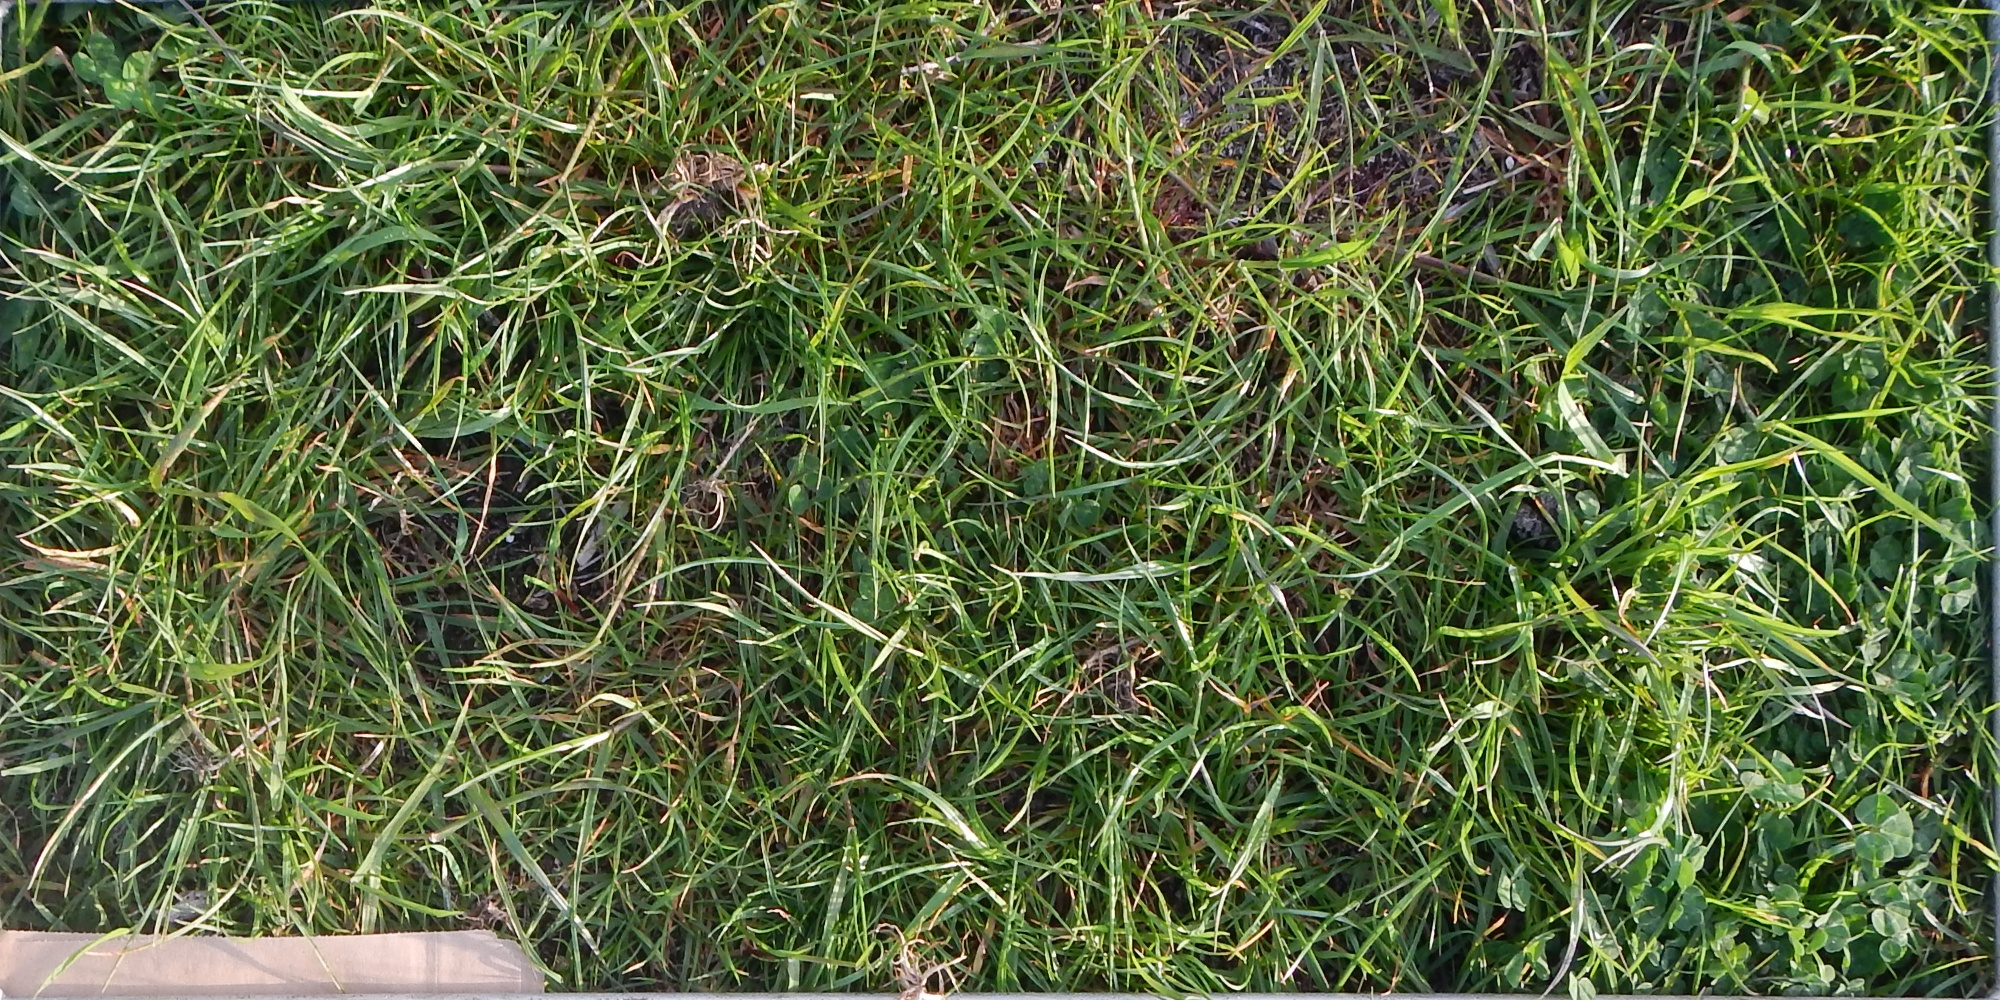

sample_id_prefix                                          ID230058600
image_path                                      train/ID230058600.jpg
Sampling_Date                                               2015/8/21
State                                                              WA
Species                                                        Clover
Pre_GSHH_NDVI                                                    0.67
Height_Ave_cm                                                     3.0
Dry_Clover_g                                                    46.83
Dry_Dead_g                                                        0.0
Dry_Green_g                                                       0.0
Dry_Total_g                                                     46.83
GDM_g                                                           46.83
image               <PIL.Image.Image image mode=RGB size=2000x1000...
Name: 217, dtype: object

In [12]:
# 查看指定sample_id_prefix的图像
sid = "ID230058600"  # 例如 "SAMPLE_000123"
row = agg_train_df.loc[agg_train_df["sample_id_prefix"] == sid].iloc[0]
display(row["image"])   # 在 notebook 里会直接显示
row